# Module 5 — Chunking

Part of the RAG Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

**Where this module starts**
- RAG (retrieval-augmented generation) answers a question in two steps:
  1. A search program finds the few texts in a collection that match the question.
  2. A language model, the kind of program behind chat assistants, reads those texts and writes the answer.
- A RAG system is built from five parts:
  1. **Chunk**: split each document into short pieces, called chunks
  2. Embed: turn each chunk into an embedding, a list of numbers that an embedding model makes from a text, so that texts with similar meaning get similar embeddings
  3. Store: keep every chunk's embedding in one table
  4. Retrieve: for each question, return the chunks that match it best
  5. Generate: the language model reads those chunks and writes the answer
- A document is split before it is searched for two reasons:
  1. The language model can read only a limited amount of text at once, so the search must return a few short pieces, not whole articles.
  2. One embedding stands for a whole text. An embedding of a long article mixes all its topics, so it matches no single question well.

**This module's point:** it builds part 1, chunk, in five ways, and grades each way with the same grades and the same test questions. The question is which way of splitting lets the search return the most sentences that support the answer, for the same amount of text the language model would read.<br>
<u>Note</u>: part 2, embed, uses an existing embedding model, nomic-embed-text. Part 3, store, keeps every chunk's embedding in one table, as in any RAG system. Part 4, retrieve, uses hybrid search: it combines the ranking of a meaning search, which compares embeddings, with the ranking of a keyword search, which counts the words a chunk shares with the question. Of three ways of searching tried on this dataset (meaning, keyword and hybrid), hybrid search found the most of the sentences that support the answers. Part 5, generate, is not run in this module: the grades judge the chunks the search returns, not answers.

**What this module measures**

The test set is a public dataset called MultiHop-RAG. It has questions about news articles, and for most questions it lists the sentences in the articles that support the answer. A listed sentence is found when the search returns a chunk that holds the whole sentence.

Two grades, each calculated for every question and then averaged over the questions, for each way of splitting:
1. Recall@k ("recall at k"): the share of a question's listed sentences held by the top k chunks the search returns, where k is the number of chunks returned.
2. MRR@k (mean reciprocal rank at k): 1 / (rank of the best-ranked chunk that holds a listed sentence), or 0 when none is in the top k.

The five ways of splitting:
1. One sentence per chunk.
2. One paragraph per chunk.
3. 100 words per chunk: the article's words cut every 100 words, wherever the cut falls.
4. 100 words per chunk, with 50 words of overlap: each chunk starts 50 words after the previous one, so most words are in two chunks.
5. 400 words per chunk.

The module runs five steps:
1. Split the articles the five ways.
2. Search every question in each way's chunks, and keep the rank of the chunk that holds each listed sentence.
3. Recall@4 and MRR@4 (recall@k and MRR@k with k = 4) of each way: the same number of chunks returned.
4. Recall and MRR of each way with k removed: in place of k, a reading limit of 400 words in total over the chunks returned for a question, a number chosen for this module, so every way hands the language model about the same number of words.
5. Why small chunks and large chunks each miss listed sentences.

**Two tags in this module**
- **[in real life]** marks a step an analyst runs to choose a way of splitting before the search goes live. A live user's question comes with no list of supporting sentences, so the analyst grades the ways of splitting on test questions that do have one.
- **[only in this module]** marks a choice that makes this module simpler or faster than a real system.

**What this module produces**
1. For each way of splitting: its number of chunks, and how many listed sentences it keeps whole.
2. Recall@4 and MRR@4 of each way.
3. Recall and MRR of each way by the number of words read, in two charts, and two tests at the 400-word reading limit: whether the sentence way's lead in recall over each other way is larger than chance, and whether the paragraph way's lead in MRR over each other way is.
4. Examples of the listed sentences that small chunks and large chunks each miss.

## From the curriculum

> ## <u>Module 5 — Chunking</u>
>
> **Concepts**
> - Why documents are split before they are searched
> - Chunk size, overlap between chunks, and splitting by sentences or paragraphs
> - The trade-off: small chunks are precise but lose context, large chunks keep
>   context but blur the match
>
> **Worked example:** several split choices, each graded with Module 4's measures.

## Lesson

### Chunks and the cuts between them

A way of splitting decides where one chunk ends and the next begins. Two kinds of cut:
- A cut by the text's own marks: the end of a sentence (".", "!" or "?" followed by a space and a capital letter or an opening quote) or the end of a paragraph (a blank line). Every sentence stays whole in one chunk.
- A cut by size: a new chunk every 100 words, wherever the 100th word falls. A sentence that runs across the 100th word is cut in two, and neither chunk holds the whole sentence.

**Overlap** repeats words between neighbouring chunks: with 100-word chunks and 50 words of overlap, chunk 1 holds words 1 to 100, chunk 2 words 51 to 150, chunk 3 words 101 to 200. A sentence that runs across word 100 is cut in chunk 1, but chunk 2, words 51 to 150, holds it whole when the sentence starts after word 50 and ends by word 150. A sentence longer than 50 words can still be cut in every chunk. The price: almost every word is stored twice, so the store holds about twice as many chunks.

### What "found" means with chunks

A search ranks every chunk, from 1 (best) down, and returns the top k. A listed sentence is **found** when a chunk in the top k holds the whole sentence. The rank of a listed sentence is the rank of the highest-ranked chunk that holds it. A listed sentence that no chunk holds whole, because a size cut split it, is never found.

### The two grades

A question's **first listed sentence** is its listed sentence with the best rank, whatever its place in the dataset's list.

**formulas**:

Recall@k of a question = (listed sentences whose rank is k or better) / (sentences listed for the question)

MRR@k of a question = 1 / (rank of the question's first listed sentence), when that rank is k or better, and 0 otherwise

In words:
- Recall@k is 1 when the top k chunks hold every listed sentence, and 0 when they hold none.
- MRR@k is 1 when a chunk holding a listed sentence is ranked first, 0.5 when ranked second, and 0 when none is in the top k.
- A way's grade is the average of the questions' grades: each question counts once.

### Same number of chunks, different number of words

Four chunks of 400 words hold up to 1,600 words. Four one-sentence chunks hold far fewer: 81% of the sentences in the articles used below are under 30 words. So at the same k, a way with large chunks returns far more text, and can find more listed sentences just because it hands the language model more to read. A fair comparison gives every way the same number of words: each way returns chunks, from rank 1 down, until the language model has about the same number of words to read.


### Is a gap between two ways real?

The test questions graded here are one set of questions. Another set written the same way would give somewhat different grades. Every way is graded on the same questions, so two ways are compared question by question:

- Difference on a question = (way A's grade on the question) − (way B's grade on the question)
- Mean difference = the average of the differences over all the questions

**formula**:

Standard error of the mean difference = (standard deviation of the differences) / √(number of questions)

95% interval = mean difference − (1.96 × standard error) to mean difference + (1.96 × standard error)

In words:
- The standard deviation of the differences says how far the differences on single questions typically are from their mean.
- The standard error says how far the mean difference would typically move from one set of test questions to another of the same size. The standard error, not the standard deviation, goes into the interval, because the interval is about the mean difference, a number calculated from a sample of questions, not about one question's difference.
- 1.96 is the standard value for a 95% interval: over many sets of test questions, intervals made this way hold the true gap 95% of the time.
- The pass rule, the standard one: the gap is real when 0 is outside the interval. When 0 is inside, the data cannot tell the two ways apart.

The code below loads the tools and checks the function that cuts by size, used by the 100-word and 400-word ways, on a short made-up text of 13 words, cut into chunks of 10 words, without and with 5 words of overlap. The printed chunks should match the description of cuts and overlap above. `common` is this playbook's shared helper file: it loads the data, calls the models, and prints tables.

In [1]:
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common
from common import show

TOP_K = 4                                          # k in Step 3
BUDGET = 400                                       # words read in Step 4
K1, B, RRF = 1.2, 0.75, 60                         # standard settings of keyword search and hybrid search (Step 2)
tidy = lambda text: " ".join(text.split())       # one space between words, no line breaks


def paragraphs(body):
    return [tidy(p) for p in body.split("\n\n") if p.strip()]


def sentences(body):
    # A sentence ends at ".", "!" or "?" followed by a space and a capital letter or an opening quote.
    return [s for p in paragraphs(body) for s in re.split(r'(?<=[.!?])\s+(?=[A-Z"“])', p)]


def fixed(body, size, overlap=0):
    words = tidy(body).split()
    step = size - overlap
    return [" ".join(words[i:i + size]) for i in range(0, max(len(words) - overlap, 1), step)]


WAYS = {"sentence": sentences,
        "paragraph": paragraphs,
        "100 words": lambda body: fixed(body, 100),
        "100 words, 50 overlap": lambda body: fixed(body, 100, 50),
        "400 words": lambda body: fixed(body, 400)}


def recall_at(ranks, k=TOP_K):
    # ranks: the ranks of one question's listed sentences, None for a sentence no chunk holds whole
    return sum(r is not None and r <= k for r in ranks) / len(ranks)


def mrr_at(ranks, k=TOP_K):
    held = [r for r in ranks if r is not None]
    return 1 / min(held) if held and min(held) <= k else 0.0


def interval(differences):
    d = np.asarray(differences, dtype=float)
    standard_error = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean() - 1.96 * standard_error, d.mean() + 1.96 * standard_error


def minus(v, decimals):
    return f"{v:.{decimals}f}".replace("-", "−")


example_text = "The phone sold out fast. The maker plans a second batch in May."
print(f"Text ({len(example_text.split())} words): {example_text}")
print()
print("10 words per chunk, no overlap:")
for i, chunk in enumerate(fixed(example_text, 10), start=1):
    print(f"  chunk {i}: {chunk}")
print()
print("10 words per chunk, 5 words of overlap:")
for i, chunk in enumerate(fixed(example_text, 10, 5), start=1):
    print(f"  chunk {i}: {chunk}")

Text (13 words): The phone sold out fast. The maker plans a second batch in May.

10 words per chunk, no overlap:
  chunk 1: The phone sold out fast. The maker plans a second
  chunk 2: batch in May.

10 words per chunk, 5 words of overlap:
  chunk 1: The phone sold out fast. The maker plans a second
  chunk 2: The maker plans a second batch in May.


Without overlap, the second sentence, "The maker plans a second batch in May.", is cut between chunk 1 and chunk 2, so no chunk holds it whole. With 5 words of overlap, chunk 2 starts at word 6, "The", and holds the second sentence whole.

## The data: the articles, the questions and the sentences they list

The dataset is MultiHop-RAG (Tang and Yang, 2024):
- 609 news articles, published between September and December 2023, each labelled with one category, such as technology or sports
- 2,556 questions about those articles. For most of them, the dataset lists sentences from the articles that support the answer.

**[only in this module]** The collection is the 172 technology articles, not all 609, because embedding every chunk of all 609 articles in five ways would take about 4 hours on this computer, against about 1 hour for the technology articles. The test questions are the questions whose listed sentences all come from technology articles. The collection holds every sentence of those articles, not only the listed ones, as a real search would.

In [2]:
corpus = common.load_corpus()
questions = common.load_questions()
articles = corpus[corpus["category"] == "technology"].reset_index(drop=True)
titles = set(articles["title"])
graded = [q for q, evidence in questions["evidence_list"].items()
          if evidence and {e["title"] for e in evidence} <= titles]
listed_of = {q: list(dict.fromkeys(tidy(e["fact"]) for e in questions["evidence_list"][q])) for q in graded}
listed = [s for q in graded for s in listed_of[q]]
unique_listed = list(dict.fromkeys(listed))

print(f"Articles = {len(corpus):,}")
print(f"Technology articles, the collection = {len(articles):,}")
print(f"Words in the technology articles = {sum(len(b.split()) for b in articles['body']):,}")
print(f"Questions whose listed sentences all come from technology articles = {len(graded):,}")
print()
print(f"Sentences listed, over those questions = {len(listed):,}")
print(f"Unique listed sentences = {len(unique_listed):,}")
print(f"Questions each unique listed sentence is listed for, on average = {len(listed):,} / {len(unique_listed):,}"
      f" = {len(listed) / len(unique_listed):.1f}")
print()
sentences_per_question = pd.Series([len(listed_of[q]) for q in graded]).value_counts().sort_index()
table = pd.DataFrame({"sentences listed": [str(n) for n in sentences_per_question.index] + ["total"],
                      "questions": [f"{v:,}" for v in sentences_per_question] + [f"{sentences_per_question.sum():,}"],
                      "questions: %": [f"{v / sentences_per_question.sum():.1%}" for v in sentences_per_question] + ["100.0%"]})
print("Test questions by the number of sentences they list:")
print()
show(table)
print()
articles_per_question = pd.Series([len({e["title"] for e in questions["evidence_list"][q]}) for q in graded]).value_counts().sort_index()
table = pd.DataFrame({"articles its listed sentences come from": [str(n) for n in articles_per_question.index] + ["total"],
                      "questions": [f"{v:,}" for v in articles_per_question] + [f"{articles_per_question.sum():,}"],
                      "questions: %": [f"{v / articles_per_question.sum():.1%}" for v in articles_per_question] + ["100.0%"]})
print("Test questions by the number of articles their listed sentences come from:")
print()
show(table)

Articles = 609
Technology articles, the collection = 172
Words in the technology articles = 330,877
Questions whose listed sentences all come from technology articles = 775

Sentences listed, over those questions = 2,249
Unique listed sentences = 182
Questions each unique listed sentence is listed for, on average = 2,249 / 182 = 12.4

Test questions by the number of sentences they list:

sentences listed  questions  questions: %
2                       219         28.3%
3                       413         53.3%
4                       143         18.5%
total                   775        100.0%

Test questions by the number of articles their listed sentences come from:

articles its listed sentences come from  questions  questions: %
2                                              238         30.7%
3                                              417         53.8%
4                                              120         15.5%
total                                          775        100.

**Observation:** every test question lists sentences from 2 to 4 different articles, so no single article holds all of a question's listed sentences.

Three limits of the grades, before any number:
1. The questions share listed sentences: each unique listed sentence is listed for 12.4 questions on average. A search that ranks a shared sentence high for one question tends to rank it high for the other questions that list it, so their grades rise and fall together, and 775 such questions tell less about how a way would do on new questions than 775 unrelated ones would, and the 95% intervals in Step 4 are somewhat narrower than they should be.
2. The dataset's list may miss sentences that also support an answer. A chunk that holds such a sentence counts as not found.
3. The grades count listed sentences only. A sentence returned as a chunk of its own, without the sentences around it in the article, may lack words the language model needs to understand it, such as the name of the company it is about. These grades do not measure that.

## Step 1 of 5: split the articles the five ways

**How many chunks does each way make, how long are they, and how many listed sentences does each way keep whole?**

**[in real life]** Every article is split each of the five ways. A way that cuts a listed sentence can never return that sentence whole, so its recall has a ceiling below 1.

In [3]:
chunks_of = {way: [c for body in articles["body"] for c in split(body)] for way, split in WAYS.items()}
words_of_chunk = {way: np.array([len(c.split()) for c in chunks]) for way, chunks in chunks_of.items()}
holders = {way: {s: [i for i, c in enumerate(chunks) if s in c] for s in unique_listed}
           for way, chunks in chunks_of.items()}

table = pd.DataFrame({
    "way of splitting": list(WAYS),
    "chunks": [f"{len(chunks_of[w]):,}" for w in WAYS],
    "words per chunk: median": [f"{np.median(words_of_chunk[w]):,.0f}" for w in WAYS],
    "words stored": [f"{words_of_chunk[w].sum():,}" for w in WAYS],
    "listed sentences held whole": [f"{sum(bool(h) for h in holders[w].values())} of {len(unique_listed)}" for w in WAYS]})
print("The five ways of splitting the technology articles:")
print()
show(table)

The five ways of splitting the technology articles:

way of splitting       chunks  words per chunk: median  words stored  listed sentences held whole
sentence               16,431                       18       330,877  182 of 182
paragraph               7,137                       43       330,877  182 of 182
100 words               3,391                      100       330,877  134 of 182
100 words, 50 overlap   6,530                      100       648,777  181 of 182
400 words                 914                      400       330,877  170 of 182


**Observation:** the sentence way and the paragraph way keep all 182 listed sentences whole, because they cut only where a sentence or a paragraph ends. In these articles a paragraph is short: a median of 43 words, against 18 for a sentence.

**Observation:** the 100-word way cuts 182 − 134 = 48 listed sentences, and the 400-word way cuts 182 − 170 = 12. A cut every 400 words makes a quarter as many cuts as a cut every 100 words, so it falls inside a listed sentence less often.

**Observation:** 50 words of overlap raises the 100-word way's whole listed sentences from 134 to 181, at the price of storing 648,777 words instead of 330,877.

The output below shows one listed sentence the 100-word way cuts:

In [4]:
cut = next(s for s in unique_listed if not holders["100 words"][s])
chunks = chunks_of["100 words"]
i = next(i for i in range(len(chunks) - 1) if cut in chunks[i] + " " + chunks[i + 1])
print(f"A listed sentence the 100-word way cuts: {cut}")
print()
print(f"End of chunk {i + 1:,}: ... {' '.join(chunks[i].split()[-12:])}")
print(f"Start of chunk {i + 2:,}: {' '.join(chunks[i + 1].split()[:12])} ...")

A listed sentence the 100-word way cuts: Indeed, ChatGPT became priority number one at OpenAI — not simply a one-off product but a development platform to build upon.

End of chunk 199: ... gave ChatGPT the ability to “hear,” “speak,” “see” and take actions. Indeed,
Start of chunk 200: ChatGPT became priority number one at OpenAI — not simply a one-off ...


## Step 2 of 5: search every question in each way's chunks

**Where does the search rank the chunk that holds each listed sentence?** Every grade in Steps 3 to 5 is calculated from these ranks, and Step 4 also uses the words in the top chunks.

**[in real life]** Each way's chunks are embedded with nomic-embed-text, and every test question is searched in each way's chunks. Two searches each rank the chunks:
1. Meaning search ranks the chunks by cosine similarity between the chunk's embedding and the question's embedding: a number from −1 to 1, higher when the two texts' meanings are closer.
2. Keyword search ranks the chunks by their BM25 (Best Matching 25) score: higher when the chunk shares more of the question's words, especially words few chunks contain, and lower for longer chunks that share the same words.

Hybrid search, the one graded here, ranks the chunks by its hybrid score, 1 / (60 + rank in meaning search) + 1 / (60 + rank in keyword search), from highest down: higher when a chunk ranks high in both searches. 60 is the standard value for this formula, not chosen here.

The embedding model expects a short label in front of every text, as its makers trained it: "search_document: " in front of a chunk, and "search_query: " in front of a question. Embedding all the chunks took about an hour on this computer, so the embeddings are saved and loaded from the saved copy.

For each question and each way, the search keeps two things: the rank of each listed sentence, which is the rank of the best-ranked chunk that holds it whole, or none when no chunk holds it whole, and the number of words in the top chunks, which Step 4 uses.

In [5]:
words_in = lambda text: re.findall(r"[a-z0-9]+", text.lower())


def keyword_search(chunks):
    # BM25 with its standard settings, K1 = 1.2 and B = 0.75. Returns a function: question -> one score per chunk.
    tokens = [words_in(c) for c in chunks]
    n = len(chunks)
    length = np.array([len(t) for t in tokens])
    holding = defaultdict(lambda: ([], []))      # word -> (chunks that hold it, times in each)
    for i, words in enumerate(tokens):
        for w, times in Counter(words).items():
            holding[w][0].append(i)
            holding[w][1].append(times)
    holding = {w: (np.array(rows), np.array(times, dtype=float)) for w, (rows, times) in holding.items()}
    length_part = K1 * (1 - B + B * length / length.mean())

    def scores(question):
        total = np.zeros(n)
        for w in dict.fromkeys(words_in(question)):
            if w in holding:
                rows, times = holding[w]
                rarity_weight = np.log(1 + (n - len(rows) + 0.5) / (len(rows) + 0.5))
                total[rows] += rarity_weight * (times * (K1 + 1)) / (times + length_part[rows])
        return total
    return scores


def ranks_of(scores):
    # Rank 1 = highest score. Ties keep the collection's order.
    order = np.argsort(-scores, kind="stable")
    ranks = np.empty(len(scores), dtype=int)
    ranks[order] = np.arange(1, len(scores) + 1)
    return ranks, order


unit = lambda m: m / np.linalg.norm(m, axis=1, keepdims=True)
question_embeddings = unit(common.embed([questions["query"][q] for q in graded], prefix="search_query: "))
KEEP = 100                                         # words counted for the top 100 chunks, enough for Step 4
results = []
for way, chunks in chunks_of.items():
    cosine = question_embeddings @ unit(common.embed(chunks, prefix="search_document: ")).T
    keyword = keyword_search(chunks)
    for j, q in enumerate(graded):
        meaning_ranks, _ = ranks_of(cosine[j])
        keyword_ranks, _ = ranks_of(keyword(questions["query"][q]))
        ranks, order = ranks_of(1 / (RRF + meaning_ranks) + 1 / (RRF + keyword_ranks))
        results.append({"question": q, "way": way,
                        "ranks": [min((int(ranks[i]) for i in holders[way][s]), default=None) for s in listed_of[q]],
                        "words read": np.cumsum(words_of_chunk[way][order[:KEEP]])})
results = pd.DataFrame(results)
print(f"Questions searched = {len(graded):,}")
print(f"Searches run = {len(graded):,} questions × {len(WAYS)} ways = {len(results):,}")

Questions searched = 775
Searches run = 775 questions × 5 ways = 3,875


## Step 3 of 5: recall@4 and MRR@4 of each way, 4 chunks returned

**Which way finds the most listed sentences when every way returns its top 4 chunks?**

**[in real life]** Each question's recall@4 and MRR@4 are calculated from the ranks kept in Step 2, for each way, and averaged over the questions. The table also gives the number of words in the top 4 chunks, averaged over the questions.

In [6]:
results["recall@4"] = results["ranks"].map(recall_at)
results["MRR@4"] = results["ranks"].map(mrr_at)
results["words in top 4"] = results["words read"].map(lambda w: w[TOP_K - 1])
grades = results.groupby("way", sort=False)[["words in top 4", "recall@4", "MRR@4"]].mean()
table = pd.DataFrame({"way of splitting": grades.index,
                      "words in top 4: average": grades["words in top 4"].map(lambda v: f"{v:,.0f}"),
                      "recall@4": grades["recall@4"].map(lambda v: f"{v:.3f}"),
                      "MRR@4": grades["MRR@4"].map(lambda v: f"{v:.3f}")})
print(f"Grades of each way of splitting, top 4 chunks, {len(graded):,} questions:")
print()
show(table)

Grades of each way of splitting, top 4 chunks, 775 questions:

way of splitting       words in top 4: average  recall@4  MRR@4
sentence                                   114     0.267  0.419
paragraph                                  282     0.346  0.615
100 words                                  396     0.297  0.528
100 words, 50 overlap                      398     0.316  0.543
400 words                                1,525     0.411  0.629


**Observation:** the 400-word way has the highest recall@4, 0.411, and the highest MRR@4, 0.629. Its top 4 chunks also hold the most words: 1,525 on average, against the sentence way's 114 (1,525 / 114 = 13.4 times as many). The 1,525 is below 4 × 400 = 1,600 because an article's last chunk holds only the words left over, fewer than 400.

**Observation:** the sentence way has the lowest recall@4, 0.267, and the lowest MRR@4, 0.419.

**Conclusion:** with the same number of chunks returned, the way with the largest chunks finds the most listed sentences, but it also hands the language model the most words to read, and every word the language model reads costs money and time. That is the trade-off: more words read tend to find more listed sentences, but cost more. So this comparison alone cannot say which way is better.

## Step 4 of 5: recall and MRR of each way when the language model reads the same number of words

**Which way finds the most listed sentences for the same number of words read?** Step 3 gave the 400-word way about 13 times as many words as the sentence way. This step compares the ways at the same number of words, in two parts:
1. Two charts, recall and MRR, where k still applies.
2. Three tables, where k is removed. In its place: a reading limit of 400 words in total over the chunks returned for a question. The three tables:
   - recall and MRR of each way
   - gaps in recall: the sentence way against each other way
   - gaps in MRR: the paragraph way against each other way

**[in real life]** In each chart, every marker is one value of k. For each way, recall@k and MRR@k are calculated for k = 1, 2, 3 and up, together with the words in the top k chunks, averaged over the questions. A line stops when its words read pass 1,600, the words in four 400-word chunks, so each line stops at its own k, the same in both charts:
- sentence: k = 53
- paragraph: k = 23
- 100 words: k = 16
- 100 words, 50 overlap: k = 16
- 400 words: k = 4

Each chart puts the words read on the horizontal axis, so the five ways are compared at the same number of words. The dashed line marks 400 words, the reading limit used in the tables below the charts.

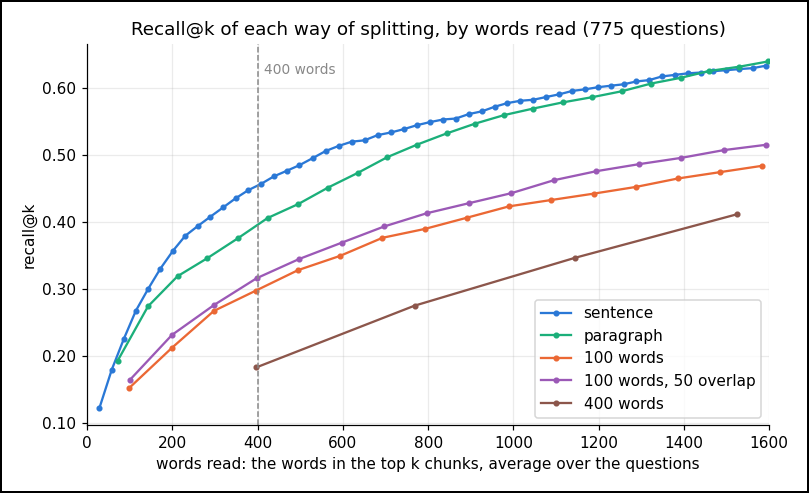

In [7]:
LIMIT = 1600
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"sentence": common.BLUE, "paragraph": common.AQUA, "100 words": common.ORANGE,
          "100 words, 50 overlap": "#9b59b6", "400 words": "#8c564b"}
for way in WAYS:
    of_way = results[results["way"] == way]
    points = []
    for k in range(1, KEEP + 1):
        words = of_way["words read"].map(lambda w: w[k - 1]).mean()
        if words > LIMIT:
            break
        points.append((words, of_way["ranks"].map(lambda r: recall_at(r, k)).mean()))
    ax.plot(*zip(*points), marker="o", markersize=3, color=colors[way], label=way)
ax.axvline(BUDGET, color=common.GREY, linestyle="--", linewidth=1)
ax.text(BUDGET + 15, 0.62, "400 words", color=common.GREY, fontsize=9)
ax.set_xlim(0, LIMIT)
ax.set_xlabel("words read: the words in the top k chunks, average over the questions")
ax.set_ylabel("recall@k")
ax.yaxis.set_major_formatter("{x:.2f}")
ax.set_title(f"Recall@k of each way of splitting, by words read ({len(graded):,} questions)")
ax.legend(loc="lower right")
plt.show()

**Observation:** up to about 1,500 words read, the sentence way's line is the highest. At about 1,500 words the paragraph way's line reaches it, so the sentence way's lead holds for short reads, not at every length. The 400-word way's line starts at about 400 words, the words in its one top chunk, and is the lowest from there on.

**Observation:** the 100-word way with 50 words of overlap is above the 100-word way without overlap at every number of words read.

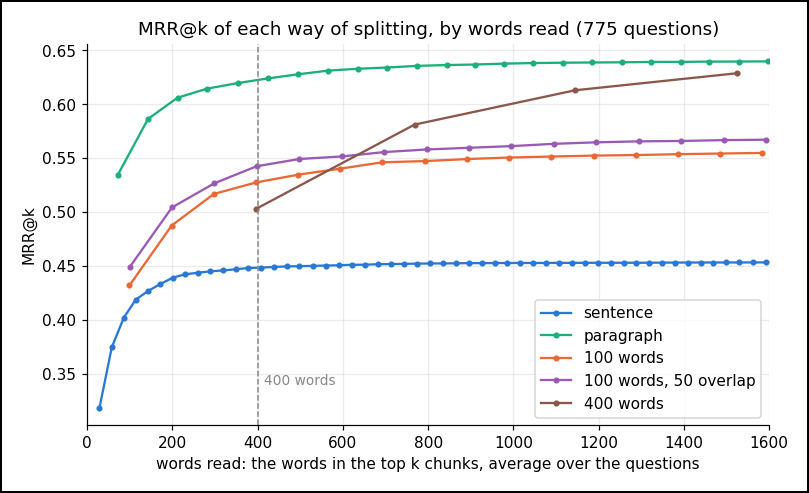

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for way in WAYS:
    of_way = results[results["way"] == way]
    points = []
    for k in range(1, KEEP + 1):
        words = of_way["words read"].map(lambda w: w[k - 1]).mean()
        if words > LIMIT:
            break
        points.append((words, of_way["ranks"].map(lambda r: mrr_at(r, k)).mean()))
    ax.plot(*zip(*points), marker="o", markersize=3, color=colors[way], label=way)
ax.axvline(BUDGET, color=common.GREY, linestyle="--", linewidth=1)
ax.text(BUDGET + 15, 0.34, "400 words", color=common.GREY, fontsize=9)
ax.set_xlim(0, LIMIT)
ax.set_xlabel("words read: the words in the top k chunks, average over the questions")
ax.set_ylabel("MRR@k")
ax.yaxis.set_major_formatter("{x:.2f}")
ax.set_title(f"MRR@k of each way of splitting, by words read ({len(graded):,} questions)")
ax.legend(loc="lower right")
plt.show()

**Observation:** up to 1,600 words read, the paragraph way's line is the highest, and the sentence way's line is the lowest. So the paragraph way's MRR lead does not depend on the 400-word reading limit.

**Observation:** every line flattens as the words read grow. A question whose first listed sentence is first found at rank k adds only 1 / k to its MRR, so finds at late ranks add little.

**Observation:** the 400-word way's line rises the most steeply, and at about 1,500 words it nearly reaches the paragraph way's line.

The charts average the words over the questions: at the same k, one question's top chunks may hold more words than another question's. To compare the ways at exactly the same number of words, each question below gets its own top k: the search returns chunks, from rank 1 down, as long as the words read stay at or below 400, and at least 1 chunk. A chunk is never cut: the search stops before the first chunk that would push the words read over 400. 400 words was chosen because it is the size of one chunk in the 400-word way, so every way returns at least one whole chunk.

**formulas**:

Recall within 400 words of a question = (listed sentences held by the chunks returned within 400 words) / (sentences listed for the question)

MRR within 400 words of a question = 1 / (rank of the question's first listed sentence), when that sentence is held by the chunks returned within 400 words, and 0 otherwise

In [9]:
def within_budget(words_read):
    return max(1, int((words_read <= BUDGET).sum()))


results["chunks within 400"] = results["words read"].map(within_budget)
results["words within 400"] = [w[k - 1] for w, k in zip(results["words read"], results["chunks within 400"])]
results["recall within 400"] = [recall_at(r, k) for r, k in zip(results["ranks"], results["chunks within 400"])]
results["MRR within 400"] = [mrr_at(r, k) for r, k in zip(results["ranks"], results["chunks within 400"])]
grades = results.groupby("way", sort=False)[["chunks within 400", "words within 400", "recall within 400", "MRR within 400"]].mean()
table = pd.DataFrame({"way of splitting": grades.index,
                      "chunks returned: average": grades["chunks within 400"].map(lambda v: f"{v:.1f}"),
                      "words read: average": grades["words within 400"].map(lambda v: f"{v:,.0f}"),
                      "recall within 400 words": grades["recall within 400"].map(lambda v: f"{v:.3f}"),
                      "MRR within 400 words": grades["MRR within 400"].map(lambda v: f"{v:.3f}")})
print(f"Recall and MRR within 400 words of each way of splitting, {len(graded):,} questions:")
print()
show(table)

Recall and MRR within 400 words of each way of splitting, 775 questions:

way of splitting       chunks returned: average  words read: average  recall within 400 words  MRR within 400 words
sentence                                   13.5                  383                    0.453                 0.448
paragraph                                   5.5                  355                    0.385                 0.620
100 words                                   4.0                  396                    0.297                 0.528
100 words, 50 overlap                       4.0                  398                    0.316                 0.543
400 words                                   1.0                  397                    0.183                 0.503


**Observation:** within 400 words, the sentence way returns 13.5 chunks on average and has the highest recall, 0.453. The 400-word way returns 1 chunk and has the lowest, 0.183. Recall continuously falls as the chunks grow.

**Observation:** MRR within 400 words orders the ways differently: the paragraph way has the highest, and the sentence way the lowest. The sentence way finds the most listed sentences within 400 words, but its first listed sentence sits lower in the list on average.

**Observation:** the two 100-word ways return exactly 4 chunks within 400 words, the same top 4 as in Step 3, so their recall within 400 words equals their recall@4 in Step 3.

**Observation:** the words read are below 400 on average, because a way stops before the chunk that would take the words read past 400.

**Observation:** at the same words read, the 100-word way's recall within 400 words is 0.316 with overlap and 0.297 without. Overlap keeps 181 − 134 = 47 more unique listed sentences whole (Step 1). This gap is not tested with an interval.

The two tables below test whether a lead is larger than chance, comparing two ways question by question, as in the lesson. The first table tests the sentence way's lead in recall over each other way. The second tests the paragraph way's lead in MRR. The 5 ways make 10 pairs, and each table tests only the 4 pairs of its leading way. The other 6 pairs, such as 100 words against 400 words, are left out to keep the tables short. The questions share listed sentences, so these intervals may be too narrow. As a stress test, the last two columns double each interval's half-width, the 1.96 × standard error on each side of the mean difference. The factor 2 is chosen for this module. A lead whose doubled interval still leaves out 0 is unlikely to come from the shared sentences alone.

In [10]:
by_question = results.pivot(index="question", columns="way", values="recall within 400")
rows = []
for other in list(WAYS)[1:]:
    d = by_question["sentence"] - by_question[other]
    se = d.std(ddof=1) / np.sqrt(len(d))
    low, high = interval(d)
    low2, high2 = d.mean() - 2 * 1.96 * se, d.mean() + 2 * 1.96 * se
    rows.append({"ways compared": f"sentence − {other}", "mean difference": minus(d.mean(), 4),
                 "standard deviation": f"{d.std(ddof=1):.4f}", "standard error": f"{se:.4f}", "95% interval": f"{minus(low, 4)} to {minus(high, 4)}",
                 "0 inside?": "yes" if low <= 0 <= high else "no",
                 "interval, half-width doubled": f"{minus(low2, 4)} to {minus(high2, 4)}",
                 "0 inside, doubled?": "yes" if low2 <= 0 <= high2 else "no"})
print(f"Gaps in recall within 400 words, {len(d):,} questions:")
print()
show(pd.DataFrame(rows))

Gaps in recall within 400 words, 775 questions:

ways compared                     mean difference  standard deviation  standard error  95% interval      0 inside?  interval, half-width doubled  0 inside, doubled?
sentence − paragraph                       0.0677              0.2702          0.0097  0.0487 to 0.0868  no         0.0297 to 0.1058              no
sentence − 100 words                       0.1554              0.3306          0.0119  0.1321 to 0.1786  no         0.1088 to 0.2019              no
sentence − 100 words, 50 overlap           0.1369              0.3052          0.0110  0.1154 to 0.1584  no         0.0939 to 0.1799              no
sentence − 400 words                       0.2699              0.3319          0.0119  0.2465 to 0.2933  no         0.2232 to 0.3166              no


**Observation:** the sentence way's lead over each of the four other ways is real: 0 is outside all four intervals, and outside all four doubled intervals too.

In [11]:
by_question = results.pivot(index="question", columns="way", values="MRR within 400")
rows = []
for other in [w for w in WAYS if w != "paragraph"]:
    d = by_question["paragraph"] - by_question[other]
    se = d.std(ddof=1) / np.sqrt(len(d))
    low, high = interval(d)
    low2, high2 = d.mean() - 2 * 1.96 * se, d.mean() + 2 * 1.96 * se
    rows.append({"ways compared": f"paragraph − {other}", "mean difference": minus(d.mean(), 4),
                 "standard deviation": f"{d.std(ddof=1):.4f}", "standard error": f"{se:.4f}", "95% interval": f"{minus(low, 4)} to {minus(high, 4)}",
                 "0 inside?": "yes" if low <= 0 <= high else "no",
                 "interval, half-width doubled": f"{minus(low2, 4)} to {minus(high2, 4)}",
                 "0 inside, doubled?": "yes" if low2 <= 0 <= high2 else "no"})
print(f"Gaps in MRR within 400 words, {len(d):,} questions:")
print()
show(pd.DataFrame(rows))

Gaps in MRR within 400 words, 775 questions:

ways compared                      mean difference  standard deviation  standard error  95% interval      0 inside?  interval, half-width doubled  0 inside, doubled?
paragraph − sentence                        0.1716              0.4311          0.0155  0.1413 to 0.2019  no         0.1109 to 0.2323              no
paragraph − 100 words                       0.0923              0.3732          0.0134  0.0660 to 0.1185  no         0.0397 to 0.1448              no
paragraph − 100 words, 50 overlap           0.0772              0.3386          0.0122  0.0534 to 0.1011  no         0.0295 to 0.1249              no
paragraph − 400 words                       0.1167              0.4701          0.0169  0.0836 to 0.1498  no         0.0505 to 0.1829              no


**Observation:** the paragraph way's lead in MRR over each of the four other ways is real: 0 is outside all four intervals, and outside all four doubled intervals too.

**Conclusion:** for 400 words read, the sentence way finds the most listed sentences, but the paragraph way ranks its first listed sentence highest, so the best way depends on which grade matters.

## Step 5 of 5: why small chunks and large chunks each miss listed sentences

**What does each size lose?** Chunk size is a trade-off: small chunks are precise but lose context, large chunks keep context but blur the match. This step compares the two ends of the size range: the sentence way, with the smallest chunks, and the 400-word way, with the largest. Each reads 400 words per question.

Chunk size causes three losses. One example of each of the first two follows, picked to show the loss clearly. The third comes by design, so it needs no example:
1. Blurred match, the 400-word way's loss: its big chunk mixes the listed sentence with other topics, so the chunk ranks low.
2. Lost context, the sentence way's loss: the sentence alone lacks words the search needs, such as the company name, so it ranks low.
3. Fewer chunks, the 400-word way's loss: within 400 words it returns 1 chunk, from one article only.

**First,** a listed sentence the sentence way ranks first and the 400-word way ranks far down:

In [12]:
def show_example(q, n):
    s = listed_of[q][n]
    print(f"Question: {questions['query'][q]}")
    print()
    print(f"Listed sentence: {s}")
    print()
    for way in ["sentence", "400 words"]:
        rank = results[(results["question"] == q) & (results["way"] == way)].iloc[0]["ranks"][n]
        print(f"Rank of the chunk that holds it: {way} = {rank:,}")


show_example(487, 3)

Question: Which company, known for being more responsive to consumer feedback in recent years and is planning to appeal an ITC decision on a patent dispute, is expected to focus on Macs and new chipsets at an upcoming event and has been criticized for enforcing uniform terms on developers, OEMs, and carriers through its store and payment system according to TechCrunch, Engadget, and two articles from The Verge?

Listed sentence: They use their store, their payments, they force developers to all have the same terms, they force OEMs and carriers to all have the same terms.

Rank of the chunk that holds it: sentence = 1
Rank of the chunk that holds it: 400 words = 25


**Observation:** the listed sentence repeats the question's words "store", "payment", "developers", "OEMs", "carriers" and "terms". Alone, the sentence matches the question closely, and the sentence way ranks it 1. In the 400-word way, the same words sit inside 400 words that also cover other topics, and the chunk ranks 25.

**Hypothesis:** the 400-word chunk's embedding stands for all the chunk's topics at once, so it is less close to the question's embedding than the one sentence's. BM25 also lowers a longer chunk's score for the same shared words. This is the blurred match. How much each search adds to the drop is not measured here.

**Second,** a listed sentence the 400-word way ranks first and the sentence way ranks far down:

In [13]:
show_example(273, 1)

Question: Between the TechCrunch report on Meta's moderation bias problem suppressing Palestinian voices published on October 19, 2023, and the TechCrunch report on Meta's alleged violations of the Children’s Online Privacy Protection Act published on November 27, 2023, was there a change in the nature of issues reported concerning Meta's platform practices?

Listed sentence: In one respect at least, however, the documentation obtained by the attorneys general of 42 states is quite specific, “and it is damning,” as AG Rob Bonta of California put it.

Rank of the chunk that holds it: sentence = 6,687
Rank of the chunk that holds it: 400 words = 1


**Observation:** the listed sentence never names Meta, the company the question names 3 times: it says "the attorneys general of 42 states". Alone, the sentence shares few of the question's words, and the sentence way ranks it 6,687. The 400-word chunk that holds it names Meta 7 times, and the 400-word way ranks it 1.

**Hypothesis:** the sentence ranks low because, cut from the text around it, it no longer names the company it is about, and the 400-word chunk ranks high because it does. This is the lost context.

**Third,** fewer chunks, the loss that comes by design: within 400 words, the 400-word way returns 1 chunk, a stretch of one article. Every test question lists sentences from 2 to 4 different articles (the data section), so 1 chunk can hold the listed sentences of one article only. The sentence way returns 13.5 chunks on average, which can come from several articles.

## Key takeaways
- A cut by size splits sentences, and a cut sentence can never be found whole. Overlap keeps most cut sentences whole, at the price of storing almost every word twice.
- With the same number of chunks returned, the largest chunks found the most listed sentences, but they also handed the language model the most words to read. A fair comparison gives every way the same number of words.
- With 400 words read, the sentence way found the most listed sentences, by more than chance. At about 1,500 words, the paragraph way caught up.
- With 400 words read, the paragraph way ranked a question's first listed sentence highest, by more than chance, measured by MRR. It stayed highest up to 1,600 words read, the end of the chart.
- Small chunks can lose context: a sentence that does not name what it is about can match the question poorly, as in the Meta example. Large chunks can blur the match, and within a word limit they fit fewer chunks, so they can come from fewer of the articles a question's listed sentences come from.

## Conclusion
When the language model reads a few hundred words, splitting the articles into sentences finds the most listed sentences, though each sentence comes without the text around it. Splitting them into paragraphs ranks a question's first listed sentence highest. So the best way depends on which grade matters.